/tmp/ipykernel_449/2675615567.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  fft_q = pd.read_csv(file_path, index_col=0, parse_dates=True)


Unique Banks: ['Manufacturers and Traders Trust Company' 'Old National Bank'
 'First Horizon Bank' 'Huntington National Bank'
 'KeyBank National Association' 'Glacier Bank' 'SouthState Bank']


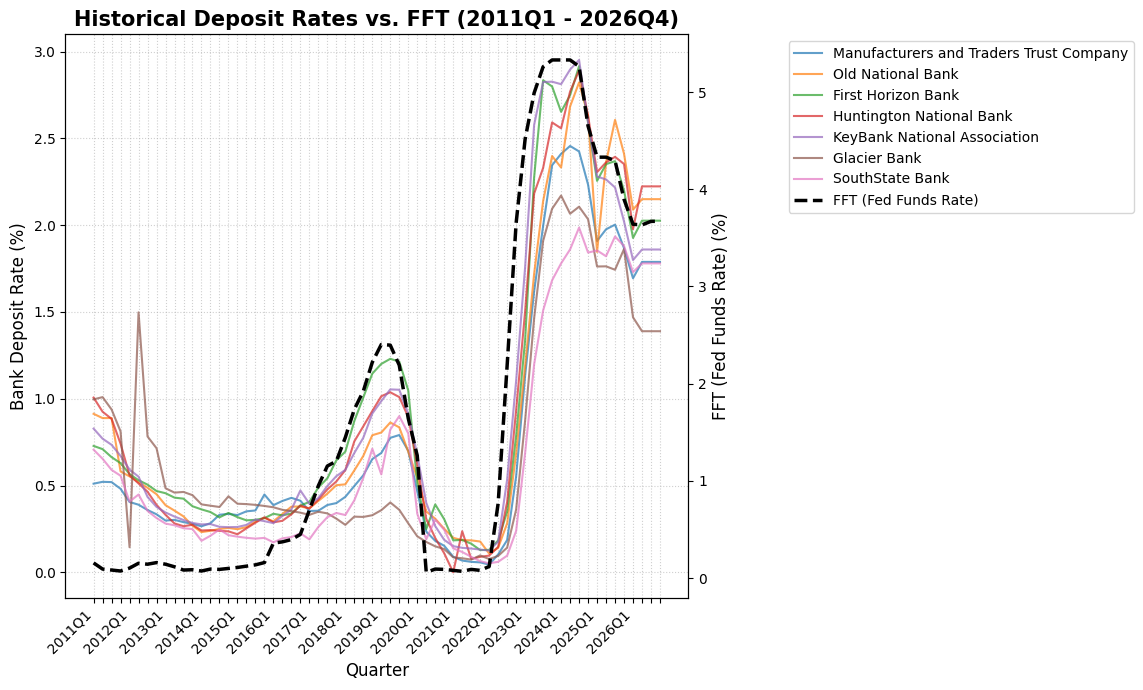

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reload FDIC and FFT data to start fresh
file_path = '/content/drive/MyDrive/Deposit Beta/consolidated_fdic_quarterly_financials_2011-2026_merger_adjusted.csv'
df = pd.read_csv(file_path)
file_path = '/content/drive/MyDrive/Deposit Beta/FFT_2011-2026.csv'
fft_q = pd.read_csv(file_path, index_col=0, parse_dates=True)
start_date ='2011-01-01'
start_q = '2011Q1'

# Convert FFT index to PeriodIndex ('Q') to match pivot_df's index
fft_q.index = fft_q.index.to_period('Q')

# Inspect the unique banks
banks = df['bank_name'].unique()
print("Unique Banks:", banks)

# Ensure sorted order for presentation
df['date'] = pd.to_datetime(df['quarter'])
df = df.sort_values(by=['bank_name', 'date']).reset_index(drop=True)

# Parse quarter column to periods for alignment
df['period'] = df['date'].dt.to_period('Q')

# Re-create pivot table with rates
pivot_df = df.pivot(index='period', columns='bank_name', values='rate_pf_clean') #switch values = 'deposit_rate' if using pre-M&A adjustment
all_quarters = pd.period_range(start=start_q, end='2026Q4', freq='Q')
pivot_df = pivot_df.reindex(all_quarters)

# Merge FFT data
final_df = pivot_df.join(fft_q, how='left')
final_df = final_df.interpolate(method='linear', limit_direction='both')

# Plotting rates with dual axes
fig, ax1 = plt.subplots(figsize=(12, 7))

# Plot bank rates on primary y-axis
lines = []
for bank in banks:
    if bank in final_df.columns:
        line, = ax1.plot(final_df.index.astype(str), final_df[bank], label=bank, alpha=0.7)
        lines.append(line)

ax1.set_xlabel('Quarter', fontsize=12)
ax1.set_ylabel('Bank Deposit Rate (%)', fontsize=12)

# Create secondary y-axis for FFT
ax2 = ax1.twinx()
if 'FFT' in final_df.columns:
    line_fft, = ax2.plot(final_df.index.astype(str), final_df['FFT'], label='FFT (Fed Funds Rate)', color='black', linewidth=2.5, linestyle='--')
    lines.append(line_fft)

ax2.set_ylabel('FFT (Fed Funds Rate) (%)', fontsize=12)

# Clean up x-axis labels: show only Q1 (e.g., '2011Q1', '2012Q1', etc.)
all_ticks = final_df.index.astype(str).tolist()
q1_ticks = [tick if tick.endswith('Q1') else '' for tick in all_ticks]

plt.title('Historical Deposit Rates vs. FFT (2011Q1 - 2026Q4)', fontsize=15, fontweight='bold')

# Set ticks containing all quarters but only display text for Q1s on ax1
ax1.set_xticks(range(len(all_ticks)))
ax1.set_xticklabels(q1_ticks, rotation=45, ha='right')

ax1.grid(True, linestyle=':', alpha=0.6)

# Add unified legend for all lines
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.show()

## Stationarity Testing

In [2]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

def run_stationarity_workflow(data_df, banks_list, significance_level=0.05):
    """
    Runs automated ADF and KPSS tests for a list of banks' rate time series.

    Parameters:
    - data_df: pandas DataFrame containing the rate series for each bank (indexed by period)
    - banks_list: list of bank names to evaluate
    - significance_level: float, default 0.05

    Returns:
    - pandas DataFrame with columns: bank_name, test_name, q_stat, p_value, pass_fail
    """
    # Disable statsmodels output warnings
    warnings.filterwarnings('ignore')

    test_results = []

    for bank in banks_list:
        if bank not in data_df.columns:
            print(f"Warning: Bank '{bank}' not found in the DataFrame columns.")
            continue

        # Drop missing values to ensure the tests run successfully
        series = data_df[bank].dropna()

        # Check for sufficient data points
        if len(series) < 10:
            print(f"Warning: Insufficient data points for bank '{bank}' (minimum 10 needed).")
            continue

        # 1. Run Augmented Dickey-Fuller (ADF) Test
        try:
            adf_stat, adf_pvalue, _, _, _, _ = adfuller(series)
            adf_pass = "PASS" if adf_pvalue <= significance_level else "FAIL"
            test_results.append({
                "bank_name": bank,
                "test_name": "ADF",
                "q_stat": adf_stat,
                "p_value": adf_pvalue,
                "pass_fail": adf_pass
            })
        except Exception as e:
            print(f"Error running ADF test for {bank}: {e}")

        # 2. Run Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test
        try:
            kpss_stat, kpss_pvalue, _, _ = kpss(series, regression='c')
            kpss_pass = "FAIL" if kpss_pvalue >= significance_level else "PASS"
            test_results.append({
                "bank_name": bank,
                "test_name": "KPSS",
                "q_stat": kpss_stat,
                "p_value": kpss_pvalue,
                "pass_fail": kpss_pass
            })
        except Exception as e:
            print(f"Error running KPSS test for {bank}: {e}")

    return pd.DataFrame(test_results)

# Execute the workflow using final_df and banks
workflow_results_df = run_stationarity_workflow(final_df, banks)
display(workflow_results_df)

,bank_name,test_name,q_stat,p_value,pass_fail
0,Manufacturers and Traders Trust Company,ADF,1.870028,0.998478,FAIL
1,Manufacturers and Traders Trust Company,KPSS,0.631062,0.019813,PASS
2,Old National Bank,ADF,-1.206334,0.670865,FAIL
3,Old National Bank,KPSS,0.651021,0.017998,PASS
4,First Horizon Bank,ADF,-1.979647,0.295568,FAIL
5,First Horizon Bank,KPSS,0.639535,0.019042,PASS
6,Huntington National Bank,ADF,0.952043,0.993733,FAIL
7,Huntington National Bank,KPSS,0.645216,0.018526,PASS
8,KeyBank National Association,ADF,-1.641734,0.461355,FAIL
9,KeyBank National Association,KPSS,0.639624,0.019034,PASS


### **<u>Note:</u>**

Only Glacier Bank shows insufficient evidence for stationarity. Everyone else is strictly non-stationary.


In [3]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

def run_first_diff_stationarity_workflow(data_df, banks_list, significance_level=0.05):
    # Disable statsmodels output warnings
    warnings.filterwarnings('ignore')

    results = []

    for bank in banks_list:
        if bank not in data_df.columns:
            continue

        # Take first difference and drop NaN values
        series_diff = data_df[bank].diff().dropna()

        if len(series_diff) < 10:
            continue

        # 1. ADF Test on first differences
        try:
            adf_stat, adf_pvalue, _, _, _, _ = adfuller(series_diff)
            adf_pass = "PASS" if adf_pvalue <= significance_level else "FAIL"
            results.append({
                "bank_name": bank,
                "test_name": "ADF (Diff)",
                "q_stat": adf_stat,
                "p_value": adf_pvalue,
                "pass_fail": adf_pass
            })
        except Exception as e:
            print(f"Error running ADF on first difference for {bank}: {e}")

        # 2. KPSS Test on first differences
        try:
            kpss_stat, kpss_pvalue, _, _ = kpss(series_diff, regression='c')
            kpss_pass = "FAIL" if kpss_pvalue >= significance_level else "PASS"
            results.append({
                "bank_name": bank,
                "test_name": "KPSS (Diff)",
                "q_stat": kpss_stat,
                "p_value": kpss_pvalue,
                "pass_fail": kpss_pass
            })
        except Exception as e:
            print(f"Error running KPSS on first difference for {bank}: {e}")

    return pd.DataFrame(results)

# Run both tests on first differences and display
diff_stationarity_results_df = run_first_diff_stationarity_workflow(final_df, list(banks))
display(diff_stationarity_results_df)

,bank_name,test_name,q_stat,p_value,pass_fail
0,Manufacturers and Traders Trust Company,ADF (Diff),-2.492835,1.172274e-01,FAIL
1,Manufacturers and Traders Trust Company,KPSS (Diff),0.107946,1.000000e-01,FAIL
2,Old National Bank,ADF (Diff),-2.969027,3.788989e-02,PASS
3,Old National Bank,KPSS (Diff),0.232648,1.000000e-01,FAIL
4,First Horizon Bank,ADF (Diff),-3.420248,1.028770e-02,PASS
5,First Horizon Bank,KPSS (Diff),0.103450,1.000000e-01,FAIL
6,Huntington National Bank,ADF (Diff),-2.357536,1.540820e-01,FAIL
7,Huntington National Bank,KPSS (Diff),0.170974,1.000000e-01,FAIL
8,KeyBank National Association,ADF (Diff),-3.551664,6.755268e-03,PASS
9,KeyBank National Association,KPSS (Diff),0.098900,1.000000e-01,FAIL


### **<u>Note:</u>**

Only Huntingtion National Bank and Manufatureres & Traders Trust Company have insufficient evidence to conclude stationarity/non-stationarity. Everyone else is strictly stationary on differencing.

Original rate TS fails to reject Unit root Hypothesis test (ADF) and stationarity test (KPSS). If the first difference reject unit root test, i.e, shows stationarity, we can test for cointegrating vectors and attempt an ECM/AECM model.